<a href="https://colab.research.google.com/github/joanne-moseley/LAP-CellposeSAM_migration_analysis/blob/main/scripts/visualise%20segmentation%20and%20tracking/visualise_segmentation_and_tracking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **visualise_segmentation_and_tracking.ipynb**
### This notebook allows for visualisation of segmentation performance for a static image or frame of a timelapse image, or visualisation of tracking on a timelapse image.

Prepare the workspace by installing and loading the required packages, including `cellpose_plotter`.

In [5]:
## install packages
%pip install -q numpy pandas scikit-image cellpose matplotlib==3.10.1 tqdm

## import packages
import numpy as np
import pandas as pd
import pathlib
from pathlib import Path
from skimage import io
import cellpose_plotter

### **Visualise segmentation of a static image**

In [16]:
## set user-adjustable parameters
proj_dir = pathlib.Path("/content/")

# parameters for visualising a static image
static_image_name = 'static_image.tif'
static_image_mask_name = 'static_image_mask.tif'
static_image_mask_dict_name = 'static_image_masks_dict.npy' # only needed to visualise segmentation, not for the tracking timelapse

save_static_image_seg_path = proj_dir / f"{Path(static_image_name).stem}_segmentation.jpg"

In [17]:
## load files for visualising a static image
# load original image stack
static_image_path = proj_dir / static_image_name
static_img = io.imread(str(static_image_path))
print(f'Image loaded. Image shape: {static_img.shape}') # should be in YX or CYX format

# load segmented mask
static_image_mask_path = proj_dir / static_image_mask_name
static_image_mask = np.squeeze(io.imread(str(static_image_mask_path)))
print(f'Mask loaded. Mask shape: {static_image_mask.shape}') # should be in YX or CYX format

Image loaded. Image shape: (1852, 1852)
Mask loaded. Mask shape: (1852, 1852)


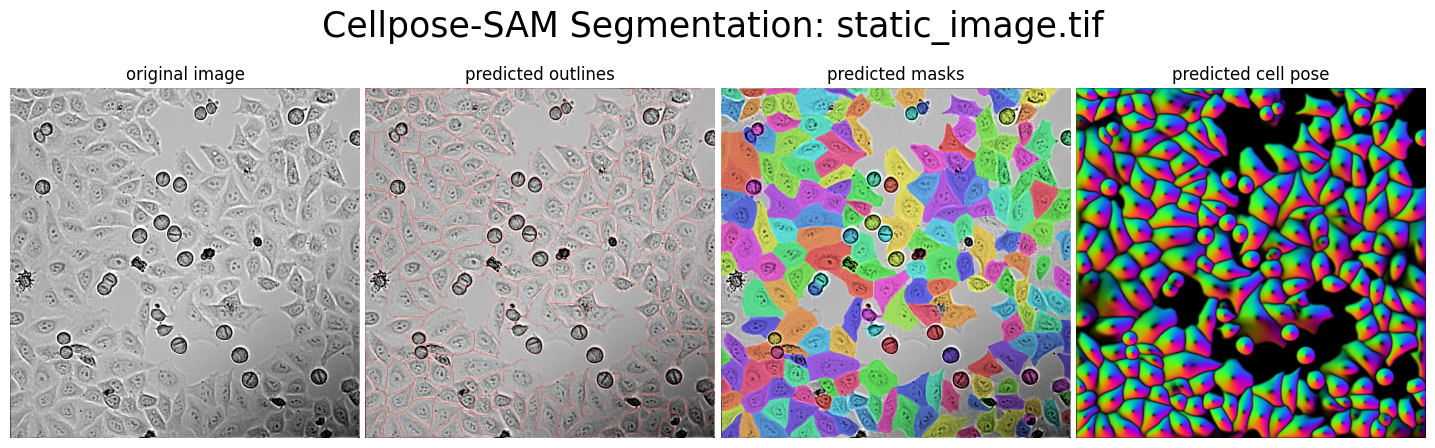

In [23]:
## visualise segmentation of a static image
# this requires the masks_dict.npy optional output from the segmentation + tracking script
# it is an optional output from the segmentation+tracking scripts because these .npy files are very large

# load segmentation results from the .npy
static_image_seg_file_path = proj_dir / static_image_mask_dict_name
static_image_seg = np.load(static_image_seg_file_path, allow_pickle=True).item()

# show the segmentation
cellpose_plotter.show_segmentation_alpha(static_img, static_image_mask, static_image_seg, mask_alpha=0.5, save_fig_path=save_static_image_seg_path, img_path=static_image_path)

### **Visualise segmentation or tracking of cells in a timelapse image**

In [ ]:
## set user-adjustable parameters
proj_dir = pathlib.Path("/content/")

# parameters for visualising a timelapse image
experiment_name = 'exp_1'
well_name = 'test'

timelapse_image_name = "test.tif"
timelapse_mask_name = 'test_masks_timeseries.tif'

# these parameters are only needed to visualise segmentation, not for the tracking timelapse
timelapse_mask_dict_name = 'test_masks_dict.npy'
save_timelapse_seg_path = proj_dir / f"{experiment_name}_{well_name}_segmentation.jpg"

# these parameters are only needed to visualise tracking, not the segmentation
tracks_name = 'exp_1_combined_tracks.csv'
save_gif_path = proj_dir / f"{experiment_name}_{well_name}_tracks.gif"

In [21]:
## load files for visualising a timelapse image
# load original image stack
timelapse_image_path = proj_dir / timelapse_image_name
timelapse_img_stack = io.imread(str(timelapse_image_path))
print(f'Image stack loaded. Stack shape: {timelapse_img_stack.shape}') # should be in TYX or TCYX format

# load segmented mask
timelapse_mask_path = proj_dir / timelapse_mask_name
timelapse_mask_stack = np.squeeze(io.imread(str(timelapse_mask_path)))
print(f'Mask stack loaded. Stack shape: {timelapse_mask_stack.shape}') # should be in TYX or TCYX format

# load tracking data (only needed for tracking visualisation)
tracks_path = proj_dir / tracks_name
track_df = pd.read_csv(str(tracks_path))

track_df_filt = track_df[track_df['file_label'] == well_name]
track_df_filt = track_df_filt[track_df_filt['experiment'] == experiment_name]
print('\nTracking data loaded. Dataframe shape: ', track_df.shape)
print('Filtered tracking data shape: ', track_df_filt.shape)

Image stack loaded. Stack shape: (5, 1904, 1776)
Mask stack loaded. Stack shape: (5, 1904, 1776)

Tracking data loaded. Dataframe shape:  (4902, 8)
Filtered tracking data shape:  (2451, 8)


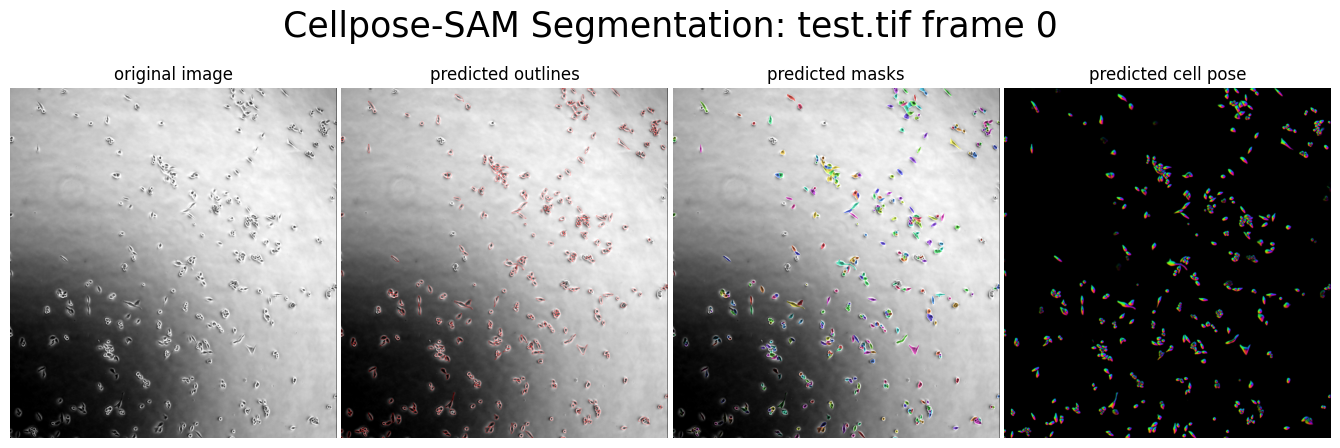

In [24]:
## visualise segmentation of a single frame
# this requires the masks_dict.npy
# the only difference between visualising a static image and a frame of a timelapse is that frame_to_display must be specified

# load segmentation results from the .npy
timelapse_seg_file_path = proj_dir / timelapse_mask_dict_name
timelapse_seg = np.load(timelapse_seg_file_path, allow_pickle=True).item()

# show the segmentation for the specified frame
cellpose_plotter.show_segmentation_alpha(timelapse_img_stack, timelapse_mask_stack, timelapse_seg, frame_to_display=0, mask_alpha=0.5, save_fig_path=save_timelapse_seg_path, img_path=timelapse_image_path)

In [25]:
## visualise cell tracking over time
cellpose_plotter.show_tracks_timelapse(timelapse_img_stack, track_df_filt, experiment=experiment_name, tracked_id_col="track_id", save_path=save_gif_path, colour_palette='red', img_path=timelapse_image_path)